# Quais estratégias de vacinação aparecem na base?

### Análise exploratória — base de vacinação (bairros: Vila São José, Bom Pastor e demais)

**Objetivo:** identificar quais estratégias de vacinação aparecem na base (`vacinas_analitico.csv`), com quais vacinas estão relacionadas, como variam ao longo do tempo e entre os bairros, e destacar registros incompletos ou inconsistentes.

Perguntas que orientam a análise (da issue):

- Quais estratégias mais aparecem e em quais vacinas?
- Como a estratégia muda ao longo do período e entre os locais?
- Pós-exposição, intensificação ou bloqueio se concentram em poucos imunizantes ou locais?
- Existem estratégias pouco representadas que merecem contextualização?

> **Nota sobre a dimensão "sala":** a base possui `nome_do_bairro`, mas não possui uma coluna `sala`. Por isso, bairro é usado aqui como dimensão de localidade.

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("vacinas_analitico.csv")

df["data_da_aplicacao"] = pd.to_datetime(
    df["data_da_aplicacao"], dayfirst=True, errors="coerce"
)

print("Registros:", len(df))
print("Bairros:", df["nome_do_bairro"].nunique())
print("Período:", df["data_da_aplicacao"].min().date(), "até", df["data_da_aplicacao"].max().date())

df.head()

Registros: 30883
Bairros: 15
Período: 2026-02-01 até 2026-06-30


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,2026-04-02,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,2026-04-02,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,2026-04-02,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,2026-04-02,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,2026-04-02,Tela de Aplicação


In [43]:
import math
ABREV = {"Monitoramento das Estratégias de Vacinação": "MEV"}

CORES = {
    "Rotina": "#3b82f6",
    "Especial": "#f59e0b",
    "Pós-exposição": "#10b981",
    "Intensificação": "#ef4444",
    "Pré-exposição": "#8b5cf6",
    "Vacinação Escolar": "#06b6d4",
    "Campanha indiscriminada": "#6b7280",
    "MEV": "#92400e",
    "Bloqueio": "#111827",
}

def fmt_milhar(n):
    return f"{n:,.0f}".replace(",", ".")

def fmt_pct(p):
    return "<0,1%" if 0 < p < 0.1 else f"{p:.1f}".replace(".", ",") + "%"

## 0. O que significa cada estratégia?

Um breve glossário, para dar contexto prático antes dos números (baseado no uso comum desses termos em campanhas de vacinação):

| Estratégia | O que costuma indicar na prática |
|---|---|
| **Rotina** | Aplicação dentro do calendário vacinal padrão, no fluxo normal das unidades de saúde. |
| **Especial** | Público ou situação que exige esquema diferenciado (ex.: condição de saúde específica, profissão de risco). |
| **Campanha indiscriminada** | Campanha aberta a toda a população-alvo, sem exigir exposição ou vínculo prévio. |
| **Vacinação Escolar** | Aplicação realizada em ambiente escolar, geralmente ligada a campanhas do calendário infantil/adolescente. |
| **Intensificação** | Reforço pontual de cobertura em uma região ou grupo, geralmente por baixa cobertura vacinal detectada. |
| **Bloqueio** | Resposta a um caso confirmado ou suspeito na região, para conter a circulação do agente — não significa, por si só, que houve surto comprovado. |
| **Pré-exposição** | Aplicada antes de um possível contato de risco (ex.: viagem, profissão exposta ao agente). |
| **Pós-exposição** | Aplicada após um contato de risco já ocorrido (ex.: acidente com animal suspeito de raiva) — não implica diagnóstico confirmado. |
| **MEV** | Monitoramento das Estratégias de Vacinação; registro administrativo/de acompanhamento do processo, não uma aplicação por exposição clínica. |
**MEV = Monitoramento das Estratégias de Vacinação.**

> **Importante:** classificações como "Especial", "Bloqueio" ou "Pós-exposição" são categorias operacionais de registro. Sozinhas, elas **não comprovam** diagnóstico, acidente ou surto — apenas indicam o protocolo seguido no momento da aplicação.

## 1. Quais estratégias aparecem, e com que frequência?

,Estratégia,Registros
0,Rotina,22646
1,Especial,7791
2,Pós-exposição,239
3,Intensificação,168
4,Pré-exposição,10
5,Vacinação Escolar,6
6,Pós,6
7,Campanha indiscriminada,5
8,19,5
9,Monitoramento das Estratégias de Vacinação,4


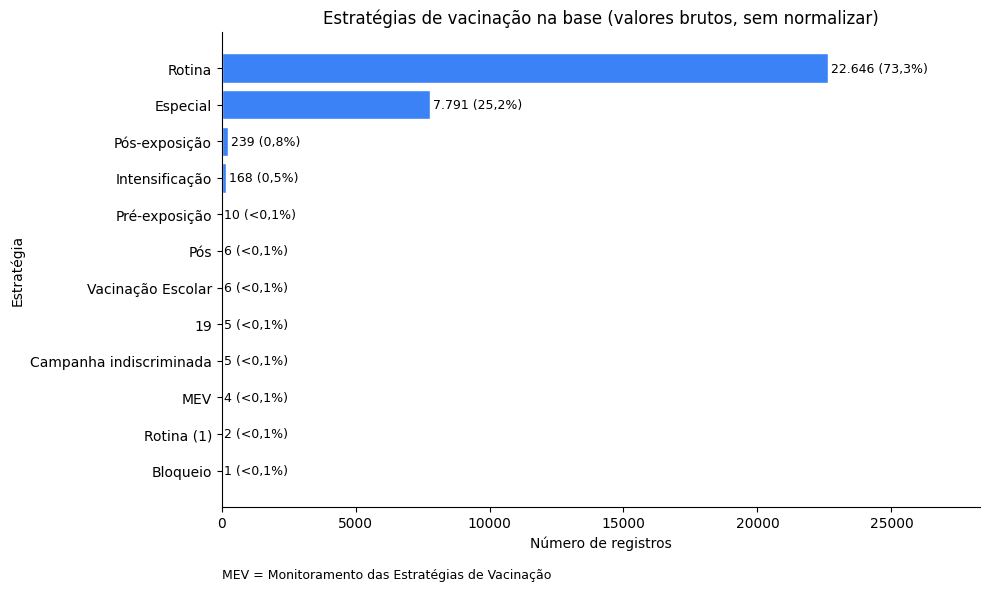

In [44]:
estrategias = (
    df["estrategia"]
    .value_counts(dropna=False)
    .rename_axis("Estratégia")
    .reset_index(name="Registros")
)

display(estrategias)

total = estrategias["Registros"].sum()
estrategias_plot = estrategias.sort_values("Registros").copy()

# Abreviação
estrategias_plot["Estratégia"] = estrategias_plot["Estratégia"].replace(
    "Monitoramento das Estratégias de Vacinação",
    "MEV"
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    estrategias_plot["Estratégia"].astype(str),
    estrategias_plot["Registros"],
    color="#3b82f6",
    edgecolor="white"
)

ax.set_title("Estratégias de vacinação na base (valores brutos, sem normalizar)")
ax.set_xlabel("Número de registros")
ax.set_ylabel("Estratégia")
ax.set_xlim(0, estrategias_plot["Registros"].max() * 1.25)

for bar, valor in zip(bars, estrategias_plot["Registros"]):
    pct = valor / total * 100
    ax.text(
        bar.get_width() + total * 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{fmt_milhar(valor)} ({fmt_pct(pct)})",
        va="center",
        fontsize=9
    )

# Legenda da sigla
ax.text(
    0,
    -0.15,
    "MEV = Monitoramento das Estratégias de Vacinação",
    transform=ax.transAxes,
    ha="left",
    fontsize=9
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Leitura

Note que aparecem valores como `'19'`, `'Pós'` e `'Rotina (1)'` junto de `'Rotina'` e `'Pós-exposição'` — isso já é um sinal de que a coluna `estrategia` tem registros truncados/inconsistentes. Vamos investigar isso na seção 7 antes de seguir com cruzamentos, para não distorcer os gráficos seguintes.

## 2. Corrigindo a rastreabilidade: código da estratégia como referência

Cada `codigo_da_estrategia` deveria mapear para um único nome. Usamos o nome mais frequente de cada código como **estratégia normalizada**, mantendo o valor original (`estrategia`) intacto para auditoria — sem perder rastreabilidade.

In [45]:
nome_por_codigo = (
    df.groupby("codigo_da_estrategia")["estrategia"]
      .agg(lambda x: x.value_counts().idxmax())
)

df["estrategia_normalizada"] = df["codigo_da_estrategia"].map(nome_por_codigo)

comparacao = (
    df.groupby("codigo_da_estrategia")["estrategia"]
      .unique()
      .reset_index()
      .rename(columns={"estrategia": "valores_originais_encontrados"})
)
comparacao["estrategia_normalizada"] = comparacao["codigo_da_estrategia"].map(nome_por_codigo)
display(comparacao)

,codigo_da_estrategia,valores_originais_encontrados,estrategia_normalizada
0,1,"[Rotina, Rotina (1), 19]",Rotina
1,2,[Especial],Especial
2,3,[Bloqueio],Bloqueio
3,4,[Intensificação],Intensificação
4,5,[Campanha indiscriminada],Campanha indiscriminada
5,9,[Monitoramento das Estratégias de Vacinação],Monitoramento das Estratégias de Vacinação
6,12,[Pré-exposição],Pré-exposição
7,13,"[Pós-exposição, Pós]",Pós-exposição
8,15,[Vacinação Escolar],Vacinação Escolar


Daqui em diante, os cruzamentos (vacina, tempo, bairro) usam `estrategia_normalizada`, para que `'Pós'` e `'Pós-exposição'` (por exemplo) sejam contados como a mesma estratégia. Os valores originais continuam disponíveis na base para quem quiser auditar.

## 3. Quais vacinas aparecem em cada estratégia?

Cruzamos **estratégia × vacina**, usando as 10 vacinas com mais registros na base.

estrategia_normalizada,Campanha indiscriminada,Especial,Intensificação,Monitoramento das Estratégias de Vacinação,Rotina,Vacinação Escolar
nome_da_vacina,,,,,,
Vacina dengue (atenuada),0,0,0,0,1241,3
Vacina difteria e tétano adulto,0,6,20,0,1582,0
Vacina febre amarela,0,0,4,2,924,0
Vacina hepatite B,0,50,0,0,1223,1
Vacina influenza trivalente,5,7130,0,0,8674,0
Vacina meningo ACWY,0,70,0,0,629,0
Vacina penta (DTP/HepB/Hib),0,0,0,0,828,1
Vacina pneumo 10,0,0,0,0,810,0
Vacina polio injetável (inativada poliomielite),0,1,0,1,1195,0


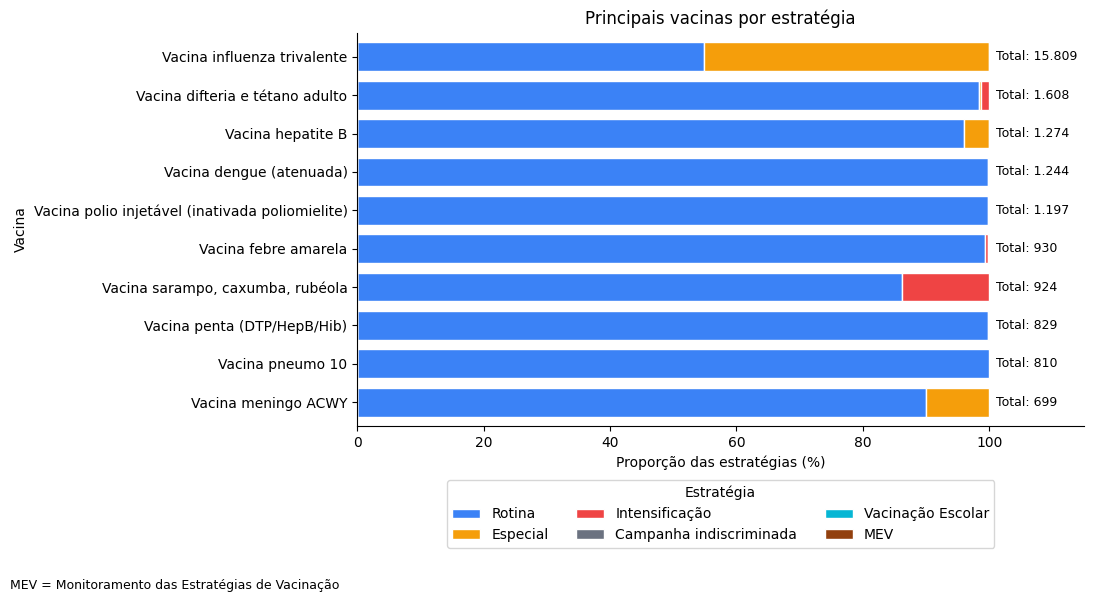

In [46]:
top_vacinas = df["nome_da_vacina"].value_counts().head(10).index

tabela = pd.crosstab(
    df.loc[df["nome_da_vacina"].isin(top_vacinas), "nome_da_vacina"],
    df.loc[df["nome_da_vacina"].isin(top_vacinas), "estrategia_normalizada"]
)

display(tabela)

totais_estrategia = tabela.sum().sort_values(ascending=False)
total_geral = totais_estrategia.sum()
tabela_plot = tabela[totais_estrategia.index].loc[tabela.sum(axis=1).sort_values().index]

# Transformar cada linha em proporção (100%)
tabela_pct = tabela_plot.div(tabela_plot.sum(axis=1), axis=0) * 100
# Abreviação da estratégia na legenda
tabela_pct = tabela_pct.rename(
    columns={
        "Monitoramento das Estratégias de Vacinação": "MEV"
    }
)

fig, ax = plt.subplots(figsize=(11, 6))

tabela_pct.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.75,
    edgecolor="white",
    color=[CORES[c] for c in tabela_pct.columns]
)

ax.set_title("Principais vacinas por estratégia")
ax.set_xlabel("Proporção das estratégias (%)")
ax.set_ylabel("Vacina")

# Total absoluto de cada vacina no final da barra
totais_vacina = tabela_plot.sum(axis=1)

for i, total_vacina in enumerate(totais_vacina):
    ax.text(
        101,
        i,
        f"Total: {total_vacina:,.0f}".replace(",", "."),
        va="center",
        fontsize=9
    )

# Legenda embaixo, horizontal
handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles,
    labels,
    title="Estratégia",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=math.ceil(len(labels) / 2)
)

ax.set_xlim(0, 115)
ax.spines[["top", "right"]].set_visible(False)

if "MEV" in tabela_pct.columns:
    fig.text(0.01, 0.01, "MEV = Monitoramento das Estratégias de Vacinação", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

## 4. Como as estratégias mudam ao longo do tempo?

Agrupamos por mês para observar a evolução de cada estratégia no período coberto pela base.

estrategia_normalizada,Bloqueio,Campanha indiscriminada,Especial,Intensificação,Monitoramento das Estratégias de Vacinação,Pré-exposição,Pós-exposição,Rotina,Vacinação Escolar
mes,,,,,,,,,
2026-02,0,0,12,19,0,1,8,1688,3
2026-03,1,4,527,56,2,1,57,4838,1
2026-04,0,0,1579,42,1,5,58,7072,0
2026-05,0,0,3014,43,1,1,41,4652,1
2026-06,0,0,2331,8,0,2,81,3872,1


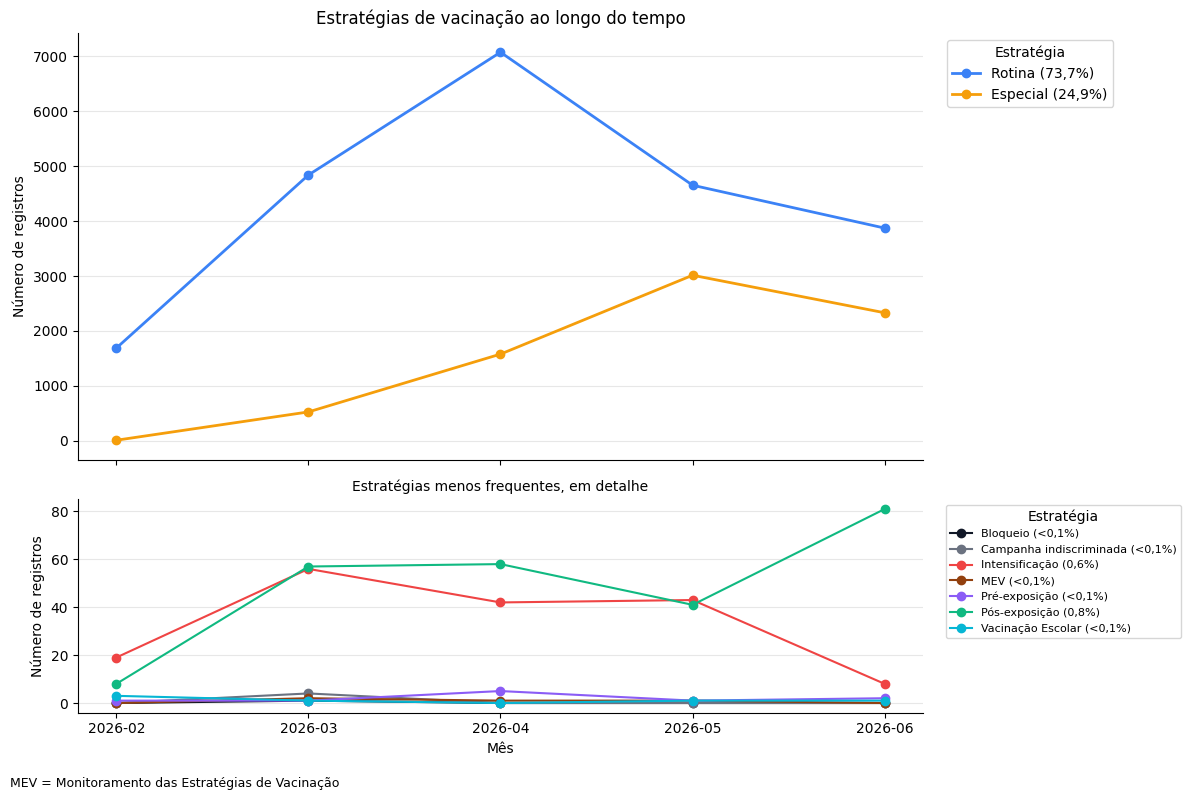

In [47]:
df["mes"] = df["data_da_aplicacao"].dt.to_period("M").astype(str)

por_mes = (
    df.dropna(subset=["data_da_aplicacao"])
      .groupby(["mes", "estrategia_normalizada"])
      .size()
      .unstack(fill_value=0)
)

display(por_mes)

totais_estrategia = por_mes.sum().sort_values(ascending=False)
total_geral = totais_estrategia.sum()
principais = totais_estrategia[totais_estrategia >= total_geral * 0.01].index
secundarias = totais_estrategia.index.difference(principais)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, height_ratios=[2, 1])

for estrategia in principais:
    pct = totais_estrategia[estrategia] / total_geral * 100
    ax1.plot(
    por_mes.index,
    por_mes[estrategia],
    marker="o",
    linewidth=2,
    color=CORES[ABREV.get(estrategia, estrategia)],
    label=f"{'MEV' if estrategia == 'Monitoramento das Estratégias de Vacinação' else estrategia} ({fmt_pct(pct)})"
)
ax1.set_title("Estratégias de vacinação ao longo do tempo")
ax1.set_ylabel("Número de registros")
ax1.grid(axis="y", alpha=0.3)
ax1.legend(title="Estratégia", bbox_to_anchor=(1.02, 1), loc="upper left")
ax1.spines[["top", "right"]].set_visible(False)

for estrategia in secundarias:
    pct = totais_estrategia[estrategia] / total_geral * 100
    ax2.plot(
    por_mes.index,
    por_mes[estrategia],
    marker="o",
    linewidth=1.5,
    color=CORES[ABREV.get(estrategia, estrategia)],
    label=f"{'MEV' if estrategia == 'Monitoramento das Estratégias de Vacinação' else estrategia} ({fmt_pct(pct)})"
)
ax2.set_title("Estratégias menos frequentes, em detalhe", fontsize=10)
ax2.set_xlabel("Mês")
ax2.set_ylabel("Número de registros")
ax2.grid(axis="y", alpha=0.3)
ax2.legend(title="Estratégia", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax2.spines[["top", "right"]].set_visible(False)

if "Monitoramento das Estratégias de Vacinação" in secundarias:
    fig.text(0.01, 0.01, "MEV = Monitoramento das Estratégias de Vacinação", fontsize=9)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

## 5. Como as estratégias se distribuem entre os bairros?

A base não tem `sala`, então usamos `nome_do_bairro` como dimensão de localidade (a base tem 15 bairros).

estrategia_normalizada,Bloqueio,Campanha indiscriminada,Especial,Intensificação,Monitoramento das Estratégias de Vacinação,Pré-exposição,Pós-exposição,Rotina,Vacinação Escolar
nome_do_bairro,,,,,,,,,
Arapongas,0,0,364,0,0,0,9,1041,0
Bom Pastor,0,1,1372,1,0,9,162,2519,0
Cidade Alta,0,0,488,11,0,1,2,1470,1
Coloninha,0,0,618,25,0,0,7,2361,1
Divineia,0,0,570,35,1,0,12,1254,2
Hercilio Luz,0,3,175,0,0,0,0,512,0
Jardim Cibele,0,0,548,24,0,0,13,1731,1
Jardim das Avenidas,0,0,283,0,1,0,7,1496,1
Mato Alto Lagoão,1,0,886,39,1,0,0,3808,0


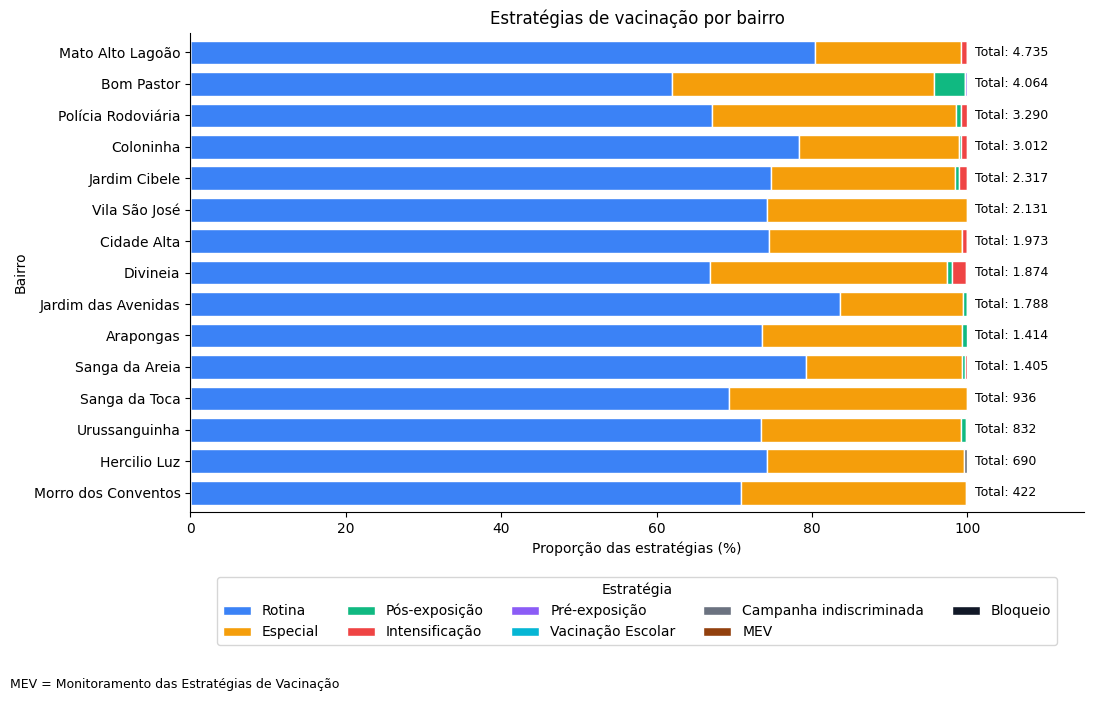

In [48]:
bairro_estrategia = pd.crosstab(
    df["nome_do_bairro"], df["estrategia_normalizada"]
)

display(bairro_estrategia)

totais_estrategia = bairro_estrategia.sum().sort_values(ascending=False)
total_geral = totais_estrategia.sum()
bairro_plot = bairro_estrategia[totais_estrategia.index].loc[bairro_estrategia.sum(axis=1).sort_values().index]

# Transformar cada bairro em proporção (100%)
bairro_pct = bairro_plot.div(bairro_plot.sum(axis=1), axis=0) * 100
bairro_pct = bairro_pct.rename(
    columns={
        "Monitoramento das Estratégias de Vacinação": "MEV"
    }
)

fig, ax = plt.subplots(figsize=(11, 7))

bairro_pct.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.75,
    color=[CORES[c] for c in bairro_pct.columns],
    edgecolor="white"
)

ax.set_title("Estratégias de vacinação por bairro")
ax.set_xlabel("Proporção das estratégias (%)")
ax.set_ylabel("Bairro")

# Total absoluto de cada bairro
totais_bairro = bairro_plot.sum(axis=1)

for i, total_bairro in enumerate(totais_bairro):
    ax.text(
        101,
        i,
        f"Total: {total_bairro:,.0f}".replace(",", "."),
        va="center",
        fontsize=9
    )

# Legenda embaixo, horizontal
handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles,
    labels,
    title="Estratégia",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=math.ceil(len(labels) / 2),
)

ax.set_xlim(0, 115)
ax.spines[["top", "right"]].set_visible(False)

if "MEV" in bairro_pct.columns:
    fig.text(0.01, 0.01, "MEV = Monitoramento das Estratégias de Vacinação", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

## 6. Foco nas estratégias menos frequentes

`Pós-exposição`, `Pré-exposição`, `Intensificação` e `Bloqueio` podem ficar escondidas ao lado de categorias muito maiores como `Rotina`. Aqui isolamos essas estratégias para ver se estão concentradas em poucos imunizantes ou bairros.

Total de registros nessas estratégias: 424
Vacinas distintas envolvidas: 8 de 41 no total
Bairros distintos envolvidos: 12 de 15 no total


estrategia_normalizada,Bloqueio,Intensificação,Pré-exposição,Pós-exposição
nome_da_vacina,,,,
Vacina HPV quadrivalente,0,14,0,0
Vacina dTpa adulto,0,1,0,0
Vacina difteria e tétano adulto,0,20,0,0
Vacina febre amarela,0,4,0,0
Vacina raiva em cultivo celular vero,0,0,10,245
Vacina rotavírus,0,1,0,0
"Vacina sarampo, caxumba, rubéola",0,128,0,0
Vacina varicela,1,0,0,0


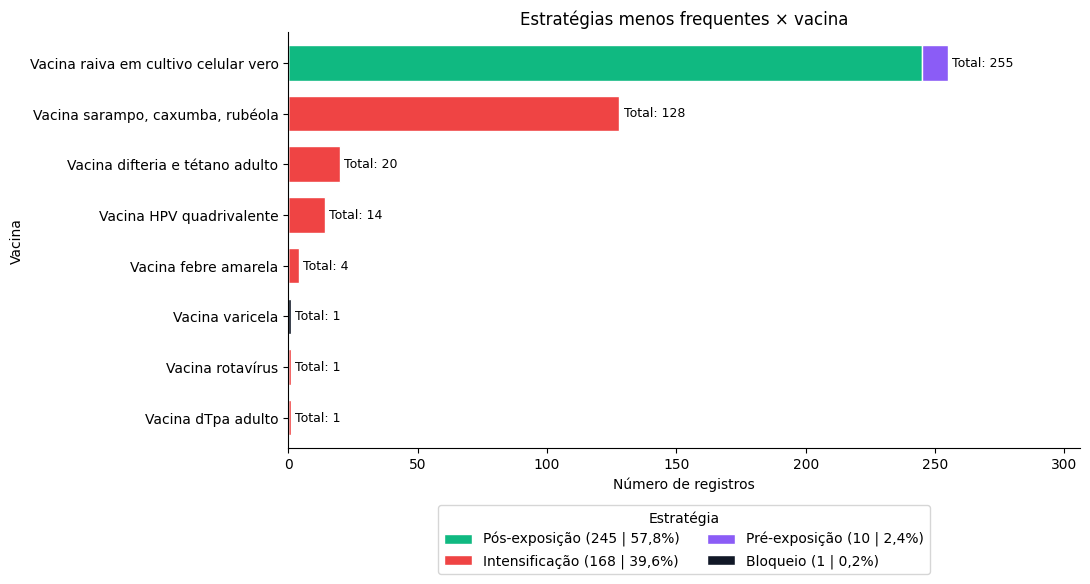

In [49]:
estrategias_especiais = [
    "Pós-exposição",
    "Pré-exposição",
    "Intensificação",
    "Bloqueio"
]

especiais = df[df["estrategia_normalizada"].isin(estrategias_especiais)]

print("Total de registros nessas estratégias:", len(especiais))
print(
    "Vacinas distintas envolvidas:",
    especiais["nome_da_vacina"].nunique(),
    "de",
    df["nome_da_vacina"].nunique(),
    "no total"
)
print(
    "Bairros distintos envolvidos:",
    especiais["nome_do_bairro"].nunique(),
    "de",
    df["nome_do_bairro"].nunique(),
    "no total"
)

especiais_por_vacina = pd.crosstab(
    especiais["nome_da_vacina"],
    especiais["estrategia_normalizada"]
)

display(especiais_por_vacina)

if not especiais_por_vacina.empty:

    # Ordem das estratégias pela quantidade total de registros
    totais_estrategia = (
        especiais_por_vacina
        .sum()
        .sort_values(ascending=False)
    )

    # Ordenar vacinas pela quantidade total de registros
    especiais_plot = (
        especiais_por_vacina[totais_estrategia.index]
        .loc[
            especiais_por_vacina.sum(axis=1)
            .sort_values()
            .index
        ]
    )

    total_geral = especiais_plot.sum().sum()
    totais_vacina = especiais_plot.sum(axis=1)

    fig, ax = plt.subplots(figsize=(11, 6))

    especiais_plot.plot(
        kind="barh",
        stacked=True,
        ax=ax,
        width=0.7,
        color=[CORES[c] for c in especiais_plot.columns],
        edgecolor="white"
    )

    ax.set_title("Estratégias menos frequentes × vacina")
    ax.set_xlabel("Número de registros")
    ax.set_ylabel("Vacina")

    # Total de registros de cada vacina no final da barra
    for i, total_vacina in enumerate(totais_vacina):
        ax.text(
            total_vacina + total_geral * 0.004,
            i,
            f"Total: {total_vacina:,.0f}".replace(",", "."),
            va="center",
            fontsize=9
        )

    # Legenda com quantidade e percentual de cada estratégia
    handles, labels = ax.get_legend_handles_labels()

    labels_legenda = [
    f"{lab} ({fmt_milhar(totais_estrategia[lab])} | "
    f"{fmt_pct(totais_estrategia[lab] / total_geral * 100)})"
    for lab in labels
    ]

    ax.legend(
        handles,
        labels_legenda,
        title="Estratégia",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=2
    )

    ax.set_xlim(0, totais_vacina.max() * 1.2)

    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.show()

### Leitura

Se a maior parte dos registros dessas estratégias estiver concentrada em uma ou duas vacinas específicas (por exemplo, raiva para `Pós-exposição`), isso é esperado pelo protocolo daquele imunizante — não é, por si só, indício de um evento fora do comum.

## 7. Registros com estratégia incompleta, truncada ou inconsistente

A issue pede que esses registros fiquem **visíveis, não removidos**. Verificamos:

- estratégia sem nome (`estrategia` nulo);
- código da estratégia ausente;
- valor de `estrategia` diferente do nome-padrão daquele código (truncamento/inconsistência, como `'19'` ou `'Pós'`);
- data da aplicação ausente.

In [50]:
sem_estrategia = df["estrategia"].isna().sum()
sem_codigo = df["codigo_da_estrategia"].isna().sum()
sem_data = df["data_da_aplicacao"].isna().sum()

inconsistentes = df["estrategia"] != df["estrategia_normalizada"]

resumo_qualidade = pd.DataFrame({
    "Problema": [
        "Estratégia sem nome",
        "Código da estratégia ausente",
        "Nome truncado/inconsistente com o padrão do código",
        "Data da aplicação ausente",
    ],
    "Registros": [sem_estrategia, sem_codigo, inconsistentes.sum(), sem_data],
})

display(resumo_qualidade)

print()
print("Exemplos de registros com nome truncado/inconsistente:")
display(
    df.loc[
        inconsistentes,
        ["estrategia", "estrategia_normalizada", "codigo_da_estrategia", "nome_da_vacina", "dose", "vacina_estrategia_e_dose"]
    ].drop_duplicates(subset=["estrategia", "codigo_da_estrategia"])
)

,Problema,Registros
0,Estratégia sem nome,0
1,Código da estratégia ausente,0
2,Nome truncado/inconsistente com o padrão do có...,13
3,Data da aplicação ausente,860



Exemplos de registros com nome truncado/inconsistente:


,estrategia,estrategia_normalizada,codigo_da_estrategia,nome_da_vacina,dose,vacina_estrategia_e_dose
15266,Rotina (1),Rotina,1,"Vacina sarampo, caxumba, rubéola e varicela",NaN,"Vacina sarampo, caxumba, rubéola e varicela (5..."
21867,19,Rotina,1,Vacina COVID,"RNAm, Pfizer - Rotina - REVACINAÇÃO","Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ..."
28706,Pós,Pós-exposição,13,Vacina raiva em cultivo celular vero,exposição - 4ª DOSE,Vacina raiva em cultivo celular vero (37) - Pó...


### Leitura

A coluna combinada `vacina_estrategia_e_dose` preserva o nome completo da estratégia mesmo quando a coluna `estrategia` foi truncada (ex.: `'19'` ou `'Pós'`). Isso confirma que a inconsistência é um problema de preenchimento/truncamento da coluna isolada, e não uma estratégia realmente diferente — e mostra por que normalizar pelo código, mantendo o original, é a forma correta de tratar isso sem perder rastreabilidade.

## 8. Relação entre estratégia, vacina e dose (sem misturar os três)

A estratégia não deve ser confundida com a vacina nem com a dose. A tabela abaixo mostra combinações completas e únicas registradas na base.

In [51]:
colunas = ["estrategia_normalizada", "codigo_da_estrategia", "nome_da_vacina", "dose", "codigo_da_dose"]

display(
    df[colunas]
    .drop_duplicates()
    .sort_values(["estrategia_normalizada", "nome_da_vacina"])
    .reset_index(drop=True)
)

,estrategia_normalizada,codigo_da_estrategia,nome_da_vacina,dose,codigo_da_dose
0,Bloqueio,3,Vacina varicela,2ª DOSE,2.0
1,Campanha indiscriminada,5,Vacina influenza trivalente,ÚNICA,9.0
2,Especial,2,"NIRSEVIMABE 0,5ml",PROFILAXIA/TRATAMENTO COM 1 FRASCO-AMPOLA/AMPOLA,59.0
3,Especial,2,"NIRSEVIMABE 1,0ml",PROFILAXIA/TRATAMENTO COM 1 FRASCO-AMPOLA/AMPOLA,59.0
4,Especial,2,"NIRSEVIMABE 1,0ml",PROFILAXIA/TRATAMENTO COM 2 FRASCOS-AMPOLAS/AM...,60.0
...,...,...,...,...,...
173,Rotina,1,Vacina vírus sincicial respiratório (recombina...,ÚNICA,9.0
174,Vacinação Escolar,15,Vacina HPV quadrivalente,ÚNICA,9.0
175,Vacinação Escolar,15,Vacina dengue (atenuada),1ª DOSE,1.0
176,Vacinação Escolar,15,Vacina hepatite B,1ª DOSE,1.0


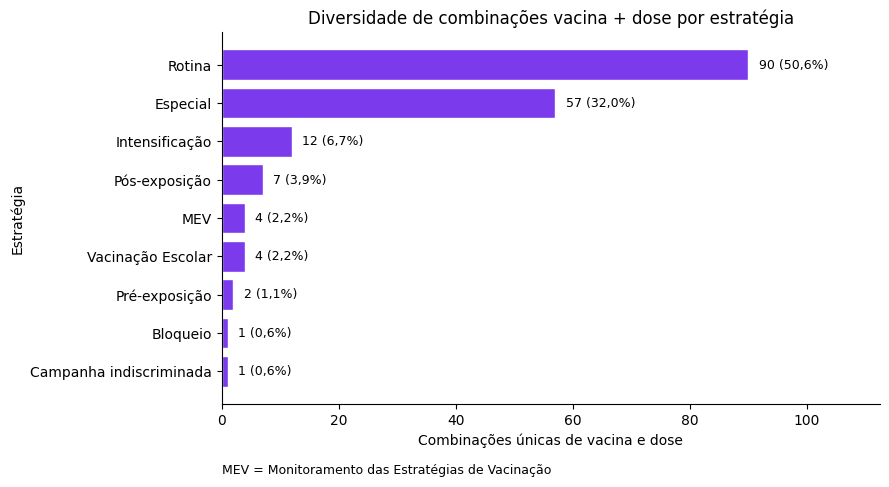

In [52]:
combinacoes_por_estrategia = (
    df[colunas]
    .drop_duplicates()["estrategia_normalizada"]
    .value_counts()
    .sort_values()
)

# Abreviação
combinacoes_por_estrategia.index = combinacoes_por_estrategia.index.to_series().replace(
    "Monitoramento das Estratégias de Vacinação",
    "MEV"
)

total_combinacoes = combinacoes_por_estrategia.sum()

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    combinacoes_por_estrategia.index.astype(str),
    combinacoes_por_estrategia.values,
    color="#7c3aed",
    edgecolor="white"
)

ax.set_title("Diversidade de combinações vacina + dose por estratégia")
ax.set_xlabel("Combinações únicas de vacina e dose")
ax.set_ylabel("Estratégia")
ax.set_xlim(0, combinacoes_por_estrategia.max() * 1.25)

for bar, valor in zip(bars, combinacoes_por_estrategia.values):
    pct = valor / total_combinacoes * 100
    ax.text(
        bar.get_width() + total_combinacoes * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{valor} ({fmt_pct(pct)})",
        va="center",
        fontsize=9
    )

# Legenda da sigla
ax.text(
    0,
    -0.19,
    "MEV = Monitoramento das Estratégias de Vacinação",
    transform=ax.transAxes,
    ha="left",
    fontsize=9
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# Conclusão

A base reúne **9 estratégias distintas** (após normalizar pelo código), aplicadas a diversos imunizantes, em 15 bairros, entre fevereiro e junho de 2026.

- **Frequência:** `Rotina` domina amplamente a base; estratégias como `Bloqueio`, `Pré-exposição` e `Pós-exposição` são bem menos frequentes e concentradas em poucos imunizantes (ex.: vacina antirrábica para pós-exposição).
- **Vacina:** cada estratégia especial tende a estar ligada a um número pequeno de vacinas específicas, coerente com o protocolo de cada uma.
- **Tempo:** a evolução mensal permite ver se alguma estratégia teve pico concentrado em um período específico.
- **Localidade:** como a base não tem `sala`, a distribuição foi analisada por bairro; alguns bairros concentram mais registros de estratégias especiais que outros.
- **Qualidade dos dados:** a coluna `estrategia` tem valores truncados/inconsistentes (`'19'`, `'Pós'`, `'Rotina (1)'`) que foram normalizados pelo código, sem descartar o valor original — e sem perder rastreabilidade com vacina e dose.

> **Interpretação importante:** `Especial`, `Pós-exposição`, `Intensificação`, `Bloqueio` etc. são classificações operacionais da vacinação registradas na base. A presença dessas categorias, isoladamente, **não comprova** diagnóstico, acidente, surto ou qualquer outra situação epidemiológica — apenas indica o protocolo seguido.

### Limitação

A base não possui uma coluna `sala`; a pergunta sobre diferenças entre salas só poderá ser respondida se essa informação for disponibilizada em uma versão futura da base.